# Model: Used car price prediction
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Car data, CarDekho (GitHub)](https://raw.githubusercontent.com/amankharwal/Website-data/master/car%20data.csv) | **Type:** regression

This notebook follows the project template and leaves the model ready for the API (`models/car.joblib` + `predictors/car.py`).

Voice command: *"JarvisTEC, price of a 2015 diesel car with 40000 km"*

## 1. Problem analysis (0.5 pt)

We want to estimate **how much a used car can be sold for** from its characteristics. The answer is a number, so it is a supervised **regression** problem.

The dataset comes from the CarDekho sales website (India) and prices are in *lakhs* of rupees (1 lakh = 100,000 rupees). The model is considered useful if it clearly beats the baseline, which is to always answer the average price; it is measured with R² and the mean absolute error (MAE).

**Support.** Linear regression and the logarithmic transformation of highly skewed variables are standard techniques of statistical learning (James et al., 2021), and here they are compared with a Random Forest (Breiman, 2001). Pudaruth (2014) applied multiple linear regression, nearest neighbors, Naive Bayes and decision trees to used-car prices, with a small dataset like this one.

In [1]:
# Libraries
import json, warnings
from datetime import date
from pathlib import Path
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

SEED = 42
BLUE, ORANGE, GRAY = '#2563eb', '#ea580c', '#94a3b8'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'font.size': 9, 'legend.frameon': False})

## 2. Data understanding (0.5 pt)


In [2]:
# Load: the copy in data/ or, if it is missing, the URL from the assignment
URL = 'https://raw.githubusercontent.com/amankharwal/Website-data/master/car%20data.csv'
LOCAL = Path('../data/car_data.csv')
cars = pd.read_csv(LOCAL if LOCAL.exists() else URL)

print('Rows:', cars.shape[0], '| columns:', cars.shape[1])
print('Nulls:', cars.isna().sum().sum(), '| duplicates:', cars.duplicated().sum(),
      '| distinct car names:', cars.Car_Name.nunique())
cars.head()

Rows: 301 | columns: 9
Nulls: 0 | duplicates: 2 | distinct car names: 98


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# Variable types and values of the categorical variables
print(cars.dtypes.to_string(), '\n')
for col in ['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']:
    print(f'{col:<13}', cars[col].value_counts().to_dict())
cars.describe().round(2)

Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Kms_Driven         int64
Fuel_Type            str
Seller_Type          str
Transmission         str
Owner              int64 

Fuel_Type     {'Petrol': 239, 'Diesel': 60, 'CNG': 2}
Seller_Type   {'Dealer': 195, 'Individual': 106}
Transmission  {'Manual': 261, 'Automatic': 40}
Owner         {0: 290, 1: 10, 3: 1}


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.00,301.00,301.00,301.00,301.00
mean,2013.63,4.66,7.63,36947.21,0.04
std,2.89,5.08,8.64,38886.88,0.25
min,2003.00,0.10,0.32,500.00,0.00
25%,2012.00,0.90,1.20,15000.00,0.00
50%,2014.00,3.60,6.40,32000.00,0.00
75%,2016.00,6.00,9.90,48767.00,0.00
max,2018.00,35.00,92.60,500000.00,3.00


There are **301 cars and 9 columns**, with no nulls and 2 duplicated rows that are removed.

| Column | Type | Meaning |
|---|---|---|
| `Selling_Price` | numeric | **Target:** selling price of the used car (lakhs) |
| `Present_Price` | numeric | Price of the same car when new (lakhs) |
| `Year` | numeric | Year of manufacture (2003–2018) |
| `Kms_Driven` | numeric | Kilometers driven |
| `Fuel_Type`, `Seller_Type`, `Transmission` | categorical | Fuel, seller type and transmission |
| `Owner` | numeric | Previous owners (almost all 0) |
| `Car_Name` | categorical | Car model: 98 distinct values |

`Car_Name` is not used: 98 categories for 299 rows would leave almost one column per car.

## 3. Data exploration (0.5 pt)


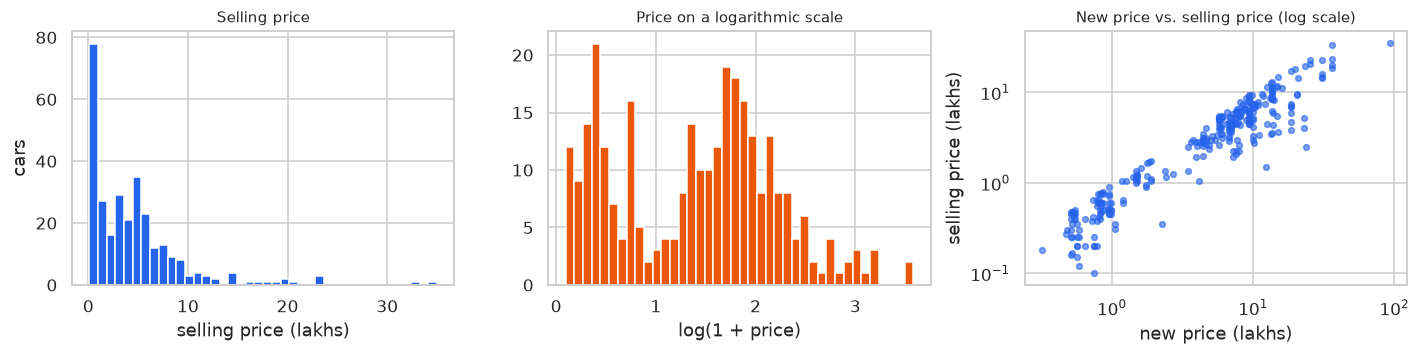

Mean: 4.59 | median: 3.51 | skewness: 2.54 | log skewness: 0.11


In [4]:
# Price distribution and relation with the new-car price
cars = cars.drop_duplicates().reset_index(drop=True)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].hist(cars.Selling_Price, bins=40, color=BLUE)
ax[0].set_xlabel('selling price (lakhs)'); ax[0].set_ylabel('cars'); ax[0].set_title('Selling price')
ax[1].hist(np.log1p(cars.Selling_Price), bins=40, color=ORANGE)
ax[1].set_xlabel('log(1 + price)'); ax[1].set_title('Price on a logarithmic scale')
ax[2].scatter(cars.Present_Price, cars.Selling_Price, s=14, alpha=0.6, color=BLUE)
ax[2].set_xscale('log'); ax[2].set_yscale('log')
ax[2].set_xlabel('new price (lakhs)'); ax[2].set_ylabel('selling price (lakhs)')
ax[2].set_title('New price vs. selling price (log scale)')
plt.tight_layout(); plt.show()

print('Mean:', round(cars.Selling_Price.mean(), 2), '| median:', cars.Selling_Price.median(),
      '| skewness:', round(cars.Selling_Price.skew(), 2),
      '| log skewness:', round(np.log1p(cars.Selling_Price).skew(), 2))

The price is very skewed: most cars are worth less than 6 lakhs and a few reach 35 (skewness 2.54). On a logarithmic scale the distribution becomes almost symmetric (0.11), and the relation with the new-car price becomes practically a straight line. This suggests **transforming the prices with a logarithm** before fitting a linear model.

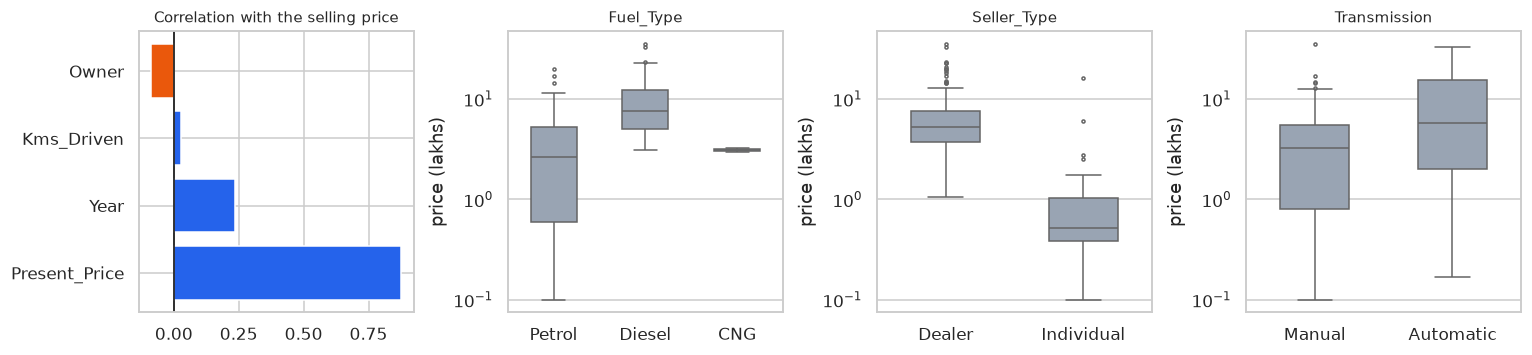

{'Present_Price': 0.876, 'Year': 0.234, 'Kms_Driven': 0.029, 'Owner': -0.088}
{'Dealer': 5.25, 'Individual': 0.515}


In [5]:
# Correlation with the price and price by categorical variable
fig, ax = plt.subplots(1, 4, figsize=(14, 3.3))
correl = cars[['Present_Price', 'Year', 'Kms_Driven', 'Owner', 'Selling_Price']].corr()['Selling_Price'].drop('Selling_Price')
ax[0].barh(correl.index, correl.values, color=[BLUE if v > 0 else ORANGE for v in correl.values])
ax[0].axvline(0, color='black', lw=1); ax[0].set_title('Correlation with the selling price')
for a, col in zip(ax[1:], ['Fuel_Type', 'Seller_Type', 'Transmission']):
    sns.boxplot(data=cars, x=col, y='Selling_Price', ax=a, color=GRAY, width=0.5, fliersize=2)
    a.set_yscale('log'); a.set_xlabel(''); a.set_ylabel('price (lakhs)'); a.set_title(col)
plt.tight_layout(); plt.show()

print(correl.round(3).to_dict())
print(cars.groupby('Seller_Type').Selling_Price.median().to_dict())

The variable that weighs the most is the **new-car price** (correlation 0.88). The year adds some (0.23) and the kilometers almost nothing on their own (0.03). Among the categorical variables, dealer cars are worth much more than private ones (median 5.25 versus 0.52 lakhs), and diesel and automatic cars are also more expensive.

## 4. Model (2 pts)

**Preparation:** duplicates and `Car_Name` are removed; the categorical variables are converted to 0/1 columns (*one-hot*); the split is 80% training and 20% test.

Four alternatives are compared, all inside a `Pipeline` so that the preparation is fitted only with the training data:

1. Baseline: always answer the mean.
2. Linear regression.
3. Random Forest.
4. Linear regression with **logarithm** on the prices and the kilometers.

Since the dataset is small, besides the split a **5-fold cross-validation** is used.

In [6]:
X = cars.drop(columns=['Selling_Price', 'Car_Name'])
y = cars['Selling_Price']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
print('Training:', len(X_tr), '| test:', len(X_te))

CATEGORICAL = ['Fuel_Type', 'Seller_Type', 'Transmission']
LOG_COLUMNS = ['Present_Price', 'Kms_Driven']
REST        = ['Year', 'Owner']

def build(model, use_log):
    """Pipeline: preparation + model. With use_log=True the target price is also transformed."""
    prepare = ColumnTransformer([
        ('categorical', OneHotEncoder(drop='first', handle_unknown='ignore'), CATEGORICAL),
        ('numeric', FunctionTransformer(np.log1p, feature_names_out='one-to-one') if use_log
                    else 'passthrough', LOG_COLUMNS),
        ('rest', 'passthrough', REST)])
    pipeline = Pipeline([('prepare', prepare), ('model', model)])
    if use_log:   # predicts log(price) and converts it back to lakhs
        return TransformedTargetRegressor(pipeline, func=np.log1p, inverse_func=np.expm1)
    return pipeline

candidates = {
    'Baseline (mean)':          build(DummyRegressor(), False),
    'Linear regression':        build(LinearRegression(), False),
    'Random Forest (300)':      build(RandomForestRegressor(300, random_state=SEED, n_jobs=-1), False),
    'Linear regression + log':  build(LinearRegression(), True)}

folds = KFold(5, shuffle=True, random_state=SEED)
rows = []
for name, model in candidates.items():
    model.fit(X_tr, y_tr)
    pred, pred_cv = model.predict(X_te), cross_val_predict(model, X, y, cv=folds)
    rows.append({'model': name,
                 'R² test': r2_score(y_te, pred), 'MAE test': mean_absolute_error(y_te, pred),
                 'R² CV': r2_score(y, pred_cv), 'MAE CV': mean_absolute_error(y, pred_cv)})
table = pd.DataFrame(rows).set_index('model').round(3)
table

Training: 239 | test: 60


,R² test,MAE test,R² CV,MAE CV
model,,,,
Baseline (mean),-0.000,3.327,-0.004,3.384
Linear regression,0.753,1.473,0.849,1.232
Random Forest (300),0.514,1.485,0.837,0.791
Linear regression + log,0.890,0.965,0.936,0.724


The best one is **linear regression with logarithm**: R² of **0.936 in cross-validation** and 0.890 on test, with a mean error of 0.72 lakhs. Linear regression without transformation stays at 0.85 and the Random Forest at 0.83: there are very few expensive cars and the forest averages them downwards, while the relation in logarithms is almost a straight line and the linear model follows it well.

## 5. Evaluation (1 pt)


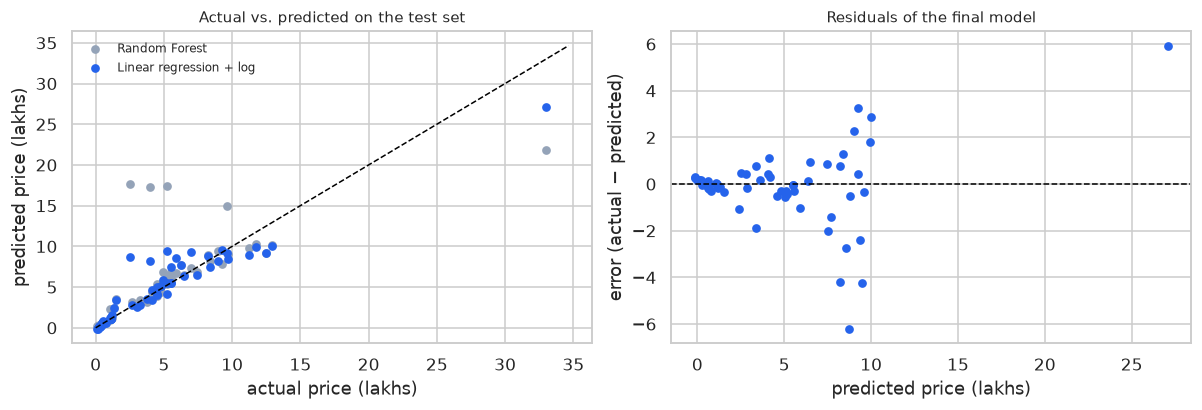

categorical__Fuel_Type_Diesel          0.281
categorical__Fuel_Type_Petrol          0.172
categorical__Seller_Type_Individual   -0.057
categorical__Transmission_Manual      -0.060
numeric__Present_Price                 0.817
numeric__Kms_Driven                   -0.027
rest__Year                             0.063
rest__Owner                            0.073

Most expensive test car: actual 33.0 | linear + log 27.1 | Random Forest 21.9


In [7]:
final = candidates['Linear regression + log']
pred = final.predict(X_te)
pred_rf = candidates['Random Forest (300)'].predict(X_te)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
limit = max(y_te.max(), pred.max()) * 1.05
ax[0].scatter(y_te, pred_rf, s=22, color=GRAY, label='Random Forest')
ax[0].scatter(y_te, pred, s=22, color=BLUE, label='Linear regression + log')
ax[0].plot([0, limit], [0, limit], color='black', lw=1, ls='--')
ax[0].set_xlabel('actual price (lakhs)'); ax[0].set_ylabel('predicted price (lakhs)')
ax[0].set_title('Actual vs. predicted on the test set'); ax[0].legend(fontsize=8)

ax[1].scatter(pred, y_te - pred, s=22, color=BLUE)
ax[1].axhline(0, color='black', lw=1, ls='--')
ax[1].set_xlabel('predicted price (lakhs)'); ax[1].set_ylabel('error (actual − predicted)')
ax[1].set_title('Residuals of the final model')
plt.tight_layout(); plt.show()

# Model coefficients (on the logarithmic scale)
inner = final.regressor_
coef = pd.Series(inner.named_steps['model'].coef_,
                 index=inner.named_steps['prepare'].get_feature_names_out()).round(3)
print(coef.to_string())
priciest = y_te.idxmax()
print(f'\nMost expensive test car: actual {y_te[priciest]} | linear + log {pred[list(y_te.index).index(priciest)]:.1f}'
      f' | Random Forest {pred_rf[list(y_te.index).index(priciest)]:.1f}')

The points of the final model stay close to the diagonal over the whole range, and the residuals show no clear pattern. The biggest difference with the Random Forest is on the most expensive test car (actual 33.0): the linear model predicts 27.1 and the forest 21.9.

The coefficients are read as percentages because the model works in logarithms: a car that costs 1% more when new sells for about **0.82% more**, and each more recent year raises the price by about **6.5%**. The kilometers subtract very little.

## 6. Conclusion (0.5 pt)

* The selling price of a used car can be estimated with a **linear regression on the logarithms**: R² of 0.94 in cross-validation and a mean error of 0.72 lakhs.
* What determines the price the most is how much the car costs new and its year; the rest adds little.
* The logarithmic transformation was the key decision: without it the same model stays at 0.85.
* Limitations: there are only 299 cars, from a single sales site in India and from 2003 to 2018, so the model is not valid for other markets or for cars very different from those in the dataset.

## Export the model
The chosen model is **retrained with all the data** and saved together with the typical value of each variable, so the API can fill in what the user does not say.

In [8]:
cv_row = table.loc['Linear regression + log']
final.fit(X, y)

bundle = {
    'pipeline': final, 'model': 'Linear regression with log transform', 'features': list(X.columns),
    'typical_values': {c: (str(X[c].mode()[0]) if c in CATEGORICAL else float(X[c].median())) for c in X.columns},
    'categories': {c: sorted(map(str, X[c].unique())) for c in CATEGORICAL},
    'sklearn': sklearn.__version__,
    'cv_metrics': {'R2': float(cv_row['R² CV']), 'MAE': float(cv_row['MAE CV'])},
    'test_metrics': {'R2': float(cv_row['R² test']), 'MAE': float(cv_row['MAE test'])},
}
joblib.dump(bundle, '../models/car.joblib', compress=3)
print('Saved ../models/car.joblib | scikit-learn', sklearn.__version__)

# API contract check
import sys; sys.path.insert(0, '..')          # to import predictors/
from predictors.car import predict
predict({'Year': 2015, 'Present_Price': 8.0, 'Kms_Driven': 40000})

Saved ../models/car.joblib | scikit-learn 1.8.0


{'prediction': 5.18,
 'unit': 'lakhs of rupees',
 'inr_equivalent': 517887,
 'imputed_fields': ['Fuel_Type', 'Seller_Type', 'Transmission', 'Owner'],
 'model': 'Linear regression with log transform',
 'note': '1 lakh = 100,000 rupees. CarDekho data (India), cars from 2003 to 2018.'}